# 03 · Answers, Citations & Refusing Out-of-Scope Questions
**Project 2 — RAG Notes Assistant.** Previous: [02 Retrieval experiments](02_retrieval_experiments.ipynb).

Retrieval finds passages. This notebook turns them into an **answer with citations**, and — just as important — makes the bot say **“I couldn't find that in your notes”** when the question is not covered. A chatbot that confidently makes things up is worse than useless for studying.

| Piece | Where |
|---|---|
| Grounding prompt (for an LLM) | `rag_notes/answer.py → build_prompt` |
| Offline answer mode (no LLM) | `ExtractiveBackend` |
| Any OpenAI-compatible LLM (Ollama / Llama 3, vLLM, OpenAI …) | `OpenAICompatBackend` |
| Refusal gate | `query_coverage` + threshold |

> **What I could and could not test:** the build environment had no access to Hugging Face or Ollama, so **no real LLM (Llama 3 / Mistral) was run**. The LLM path is tested against a local *fake* OpenAI-compatible server (request format, citations parsing, fallback). Real-LLM answer quality is **unmeasured**.

In [1]:
import sys, json, threading, time, warnings; warnings.filterwarnings('ignore'); sys.path.insert(0, '.')
from http.server import BaseHTTPRequestHandler, HTTPServer
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from rag_notes.index import Index
from rag_notes.answer import RAG, ExtractiveBackend, OpenAICompatBackend, build_prompt, query_coverage, REFUSAL, SYSTEM_PROMPT
from rag_notes.evaluate import load_golden, matches
sns.set_theme(style='whitegrid')
index = Index.build('data/notes'); golden = load_golden('eval/golden.json')
print(len(index.chunks), 'chunks')

582 chunks


## 1. The grounding prompt

In [2]:
print(SYSTEM_PROMPT)

You are a study assistant. Answer ONLY from the numbered context passages below, which come from the student's own notes. Cite passages like [1] or [2][3] after the sentences they support. Keep code in fenced code blocks. If the context does not contain the answer, reply exactly: "I couldn't find that in your notes." Never use outside knowledge.


The rules for a language model: use **only** the numbered passages, cite them as `[1]`, keep code in fences, and answer with one exact sentence when the answer isn't there. The exact sentence matters — the app and tests can detect a refusal by string match.

In [3]:
hits = index.search('How do I join two tables on a common column like in SQL?', k=3)
msgs = build_prompt('How do I join two tables on a common column like in SQL?', hits)
print(msgs[1]['content'][:1500])

Context:

[1] (pandas/05_groupby_merging.md › 9. `pivot_table()` — Excel-Style Summary Tables)
## 9. `pivot_table()` — Excel-Style Summary Tables

```python
pivot = sales.pivot_table(values='Revenue', index='Region', columns='Product', aggfunc='sum', fill_value=0)
print(pivot)
```

Output:

```text
Product  Keyboard  Laptop  Mouse
Region                          
East            0  150000   2400
North       15000  250000   3000
South           0  400000   4000
```

```python
pivot_with_margins = sales.pivot_table(values='Revenue', index='Region', columns='Product', aggfunc='sum', fill_value=0, margins=True)
print(pivot_with_margins)
```

Output:

```text
Product  Keyboard  Laptop  Mouse     All
Region                                  
East            0  150000   2400  152400
North       15000  250000   3000  268000
South           0  400000   4000  404000
All         15000  800000   9400  824400
```

[2] (pandas/05_groupby_merging.md › 11. `merge()` — SQL-Style Joins)
## 11. `merge()` 

In [4]:
print('prompt size:', sum(len(m['content']) for m in msgs), 'characters ≈', sum(len(m['content']) for m in msgs)//4, 'tokens')

prompt size: 3670 characters ≈ 917 tokens


Passages are labelled with their file and section so the model (and the user) can trace every claim back to the notes.

## 2. Offline answer mode (no LLM)

In [5]:
rag = RAG(index)
ans = rag.ask('How do I join two tables on a common column like in SQL?')
print(ans.text[:1300]); print('\nbackend:', ans.backend, '| answered:', ans.answered, '| coverage: %.2f' % ans.confidence)
pd.DataFrame(ans.sources)

**From your notes — 9. `pivot_table()` — Excel-Style Summary Tables** [1]

```python
pivot = sales.pivot_table(values='Revenue', index='Region', columns='Product', aggfunc='sum', fill_value=0)
print(pivot)
```

```python
pivot_with_margins = sales.pivot_table(values='Revenue', index='Region', columns='Product', aggfunc='sum', fill_value=0, margins=True)
print(pivot_with_margins)
```

---

**From your notes — 11. `merge()` — SQL-Style Joins** [2]

```python
inner_join = pd.merge(customers, orders, on='CustomerID', how='inner')
print('INNER JOIN (only matches):\n', inner_join)
```

```text
INNER JOIN (only matches):
    CustomerID   Name  OrderID  Amount
0           1  Rahul      101     500
1           2  Aisha      102    1200
2           2  Aisha      103     800
```

backend: extractive | answered: True | coverage: 1.00


,n,source,section,series,kind
0,1,pandas/05_groupby_merging.md,9. `pivot_table()` — Excel-Style Summary Tables,pandas,notes
1,2,pandas/05_groupby_merging.md,11. `merge()` — SQL-Style Joins,pandas,notes
2,3,pandas/05_groupby_merging.md,11. `merge()` — SQL-Style Joins,pandas,notes
3,4,pandas/03_indexing_selecting.md,7. `query()` — SQL-Like Filtering Syntax,pandas,notes
4,5,numpy/01_numpy_basics.md,8. Array vs List — Mutability Behaviour,numpy,notes


The **extractive** backend returns the most relevant paragraphs and code from the top passages, with citations. It cannot paraphrase or combine facts, but it **cannot hallucinate** either — every word comes from your notes.

In [6]:
for q in ['What is the difference between ravel and flatten?','How do I choose the number of clusters for k-means?']:
    a=rag.ask(q); print('Q:',q); print(a.text[:700]); print('   sources:', [(s['n'], s['section'][:40]) for s in a.sources[:3]]); print('='*90)

Q: What is the difference between ravel and flatten?
**From your notes — 3. `ravel()` vs `flatten()` — Flattening to 1-D** [1]

raveled = matrix.ravel()     # returns a VIEW (fast, shares memory)
flattened = matrix.flatten() # returns a COPY (safe, independent)

print('ravel():  ', raveled)
print('flatten():', flattened)

---

**From your notes — 18. `datetime64` and `timedelta64` — Date Arrays** [2]

```python
order_dates = np.array(['2026-01-15', '2026-02-20', '2026-03-05'], dtype='datetime64')
print(order_dates)
print('dtype:', order_dates.dtype)

```text
['2026-01-15' '2026-02-20' '2026-03-05']
dtype: datetime64[D]
   sources: [(1, '3. `ravel()` vs `flatten()` — Flattening'), (2, '18. `datetime64` and `timedelta64` — Dat'), (3, '04 — Reshaping & Stacking in NumPy (Pree')]
Q: How do I choose the number of clusters for k-means?
**From your notes — 2. Finding the Right Number of Clusters — Elbow Method** [1]

```python
inertias = []
k_range = range(1, 11)
for k in k_range:
    km = KM

## 3. The refusal gate

**Idea:** if the notes don't cover a topic, many of the question's content words won't appear in any retrieved passage. We measure **coverage** = share of the question's (non-stop-word) terms that appear in the top-5 passages, and refuse below a threshold.

In [7]:
def cov(q, k=5): return query_coverage(index, q, index.search(q, k))
for q in ['How do I join two tables on a common column like in SQL?','How do I deploy pods on Kubernetes?','What is the capital of France?','How do I run a t-test with scipy?']:
    print(f'{cov(q):.2f}  {q}')

1.00  How do I join two tables on a common column like in SQL?
0.00  How do I deploy pods on Kubernetes?
0.00  What is the capital of France?
0.67  How do I run a t-test with scipy?


In [8]:
dI=[i for i in golden['in_scope'] if i['split']=='dev']; dO=[i for i in golden['out_of_scope'] if i['split']=='dev']
in_dev=np.array([cov(i['question']) for i in dI]); out_dev=np.array([cov(i['question']) for i in dO])
print('DEV in-scope coverage: mean %.2f | out-of-scope: mean %.2f' % (in_dev.mean(), out_dev.mean()))

DEV in-scope coverage: mean 0.75 | out-of-scope: mean 0.33


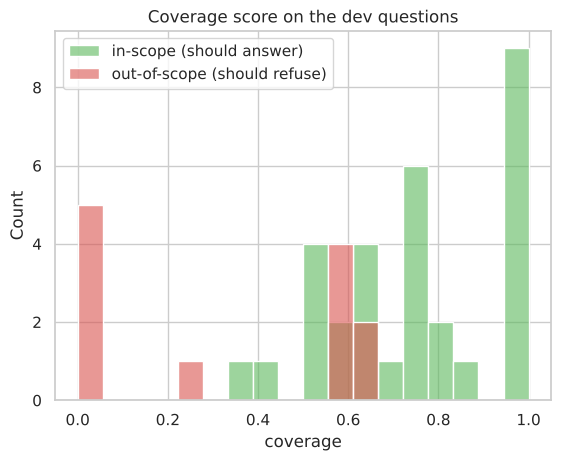

In [9]:
sns.histplot(in_dev,bins=12,color='#5cb85c',label='in-scope (should answer)',alpha=.6); sns.histplot(out_dev,bins=12,color='#d9534f',label='out-of-scope (should refuse)',alpha=.6); plt.xlabel('coverage'); plt.legend(); plt.title('Coverage score on the dev questions'); plt.show()

The two groups **overlap**: a single coverage number cannot separate them perfectly. So choosing the threshold is a trade-off between wrongly refusing good questions and wrongly answering off-topic ones.

In [10]:
ths=np.round(np.arange(.30,.91,.05),2)
curve=pd.DataFrame({'threshold':ths,'answered in-scope':[(in_dev>=t).mean() for t in ths],'refused out-of-scope':[(out_dev<t).mean() for t in ths]}); curve['balanced']=(curve.iloc[:,1]+curve.iloc[:,2])/2; curve.round(2)

,threshold,answered in-scope,refused out-of-scope,balanced
0,0.30,1.00,0.50,0.75
1,0.35,0.97,0.50,0.73
2,0.40,0.97,0.50,0.73
3,0.45,0.94,0.50,0.72
4,0.50,0.94,0.50,0.72
5,0.55,0.81,0.50,0.65
6,0.60,0.81,0.58,0.69
7,0.65,0.74,0.92,0.83
8,0.70,0.61,1.00,0.81
9,0.75,0.58,1.00,0.79


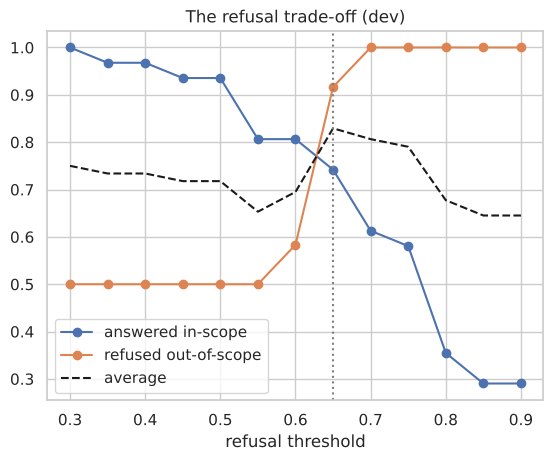

In [11]:
plt.plot(curve.threshold,curve['answered in-scope'],'o-',label='answered in-scope'); plt.plot(curve.threshold,curve['refused out-of-scope'],'o-',label='refused out-of-scope'); plt.plot(curve.threshold,curve.balanced,'k--',label='average'); plt.axvline(.65,color='gray',ls=':'); plt.xlabel('refusal threshold'); plt.legend(); plt.title('The refusal trade-off (dev)'); plt.show()

In [12]:
best=curve.loc[curve.balanced.idxmax()]; print('best balanced threshold on dev:', best.threshold, '→ answers %.0f%% of in-scope, refuses %.0f%% of out-of-scope' % (best['answered in-scope']*100, best['refused out-of-scope']*100))

best balanced threshold on dev: 0.65 → answers 74% of in-scope, refuses 92% of out-of-scope


### 3.1 Does weighting words by rarity help?

In [13]:
in_w=np.array([query_coverage(index,i['question'],index.search(i['question'],5),weighted=True) for i in dI]); out_w=np.array([query_coverage(index,i['question'],index.search(i['question'],5),weighted=True) for i in dO])
rows=[]
for name,a,b in [('plain',in_dev,out_dev),('rarity-weighted',in_w,out_w)]:
    best=max(((((a>=t).mean()+(b<t).mean())/2),t) for t in ths); rows.append(dict(variant=name,best_balanced=round(best[0],3),at_threshold=best[1]))
pd.DataFrame(rows)

,variant,best_balanced,at_threshold
0,plain,0.829,0.65
1,rarity-weighted,0.829,0.55


Rarity weighting did **not** beat plain coverage on dev, so the simpler plain version stays. Threshold **0.65** is used as the default (the app exposes it as a “strictness” slider).

## 4. Evaluate the gate on the TEST questions (once)

In [14]:
dI_t=[i for i in golden['in_scope'] if i['split']=='test']; dO_t=[i for i in golden['out_of_scope'] if i['split']=='test']
in_t=np.array([cov(i['question']) for i in dI_t]); out_t=np.array([cov(i['question']) for i in dO_t])
TH=0.65
res=pd.DataFrame({'dev':[(in_dev>=TH).mean(),(out_dev<TH).mean()],'test':[(in_t>=TH).mean(),(out_t<TH).mean()]},index=['answered in-scope questions','refused out-of-scope questions']).round(3); res

,dev,test
answered in-scope questions,0.742,0.903
refused out-of-scope questions,0.917,0.917


In [15]:
print('TEST: n in-scope =',len(in_t),', n out-of-scope =',len(out_t))
refused_wrongly=[i['question'] for i,c in zip(dI_t,in_t) if c<TH]; answered_wrongly=[i['question'] for i,c in zip(dO_t,out_t) if c>=TH]
print('\nWrongly refused (in-scope):'); [print('  ',q) for q in refused_wrongly]; print('\nWrongly answered (out-of-scope):'); [print('  ',q) for q in answered_wrongly]

TEST: n in-scope = 31 , n out-of-scope = 12

Wrongly refused (in-scope):
   How do I draw a circular chart showing proportions?
   How do I show uncertainty as whiskers on data points?
   How do I show a scatter plot with the distributions of each axis on the sides?

Wrongly answered (out-of-scope):
   How do I run a t-test with scipy?


[None]

With only 12 out-of-scope test questions, each is ≈ 8 points, so treat these as rough. The one wrongly answered off-topic question is a **hard negative**: a statistics question (t-test) that shares many words with the notes' statistics and scikit-learn material. Questions that sound close to the notes are exactly what a word-overlap gate struggles with.

### 4.2 What the user sees on a refusal

In [16]:
a=RAG(index).ask('How do I deploy pods on Kubernetes?'); print(a.text); print('answered:',a.answered,'| coverage: %.2f' % a.confidence); pd.DataFrame(a.sources)[['source','section']]

I couldn't find that in your notes.
answered: False | coverage: 0.00


,source,section
0,interview-qa/04_pandas_interview_qna.md,Q21. How do you subtract the row mean from eac...
1,seaborn/03_distribution_plots.md,4. 2-D `kdeplot()` — Bivariate Density
2,seaborn/03_distribution_plots.md,3. `kdeplot()` — Smooth Density Curve
3,seaborn/05_titanic_eda.md,7. Fare Distribution — `kdeplot()`
4,exercises/100_numpy_exercises.md,4. How to find the memory size of any array (★☆☆)


On refusal the app still shows the *closest passages*, clearly labelled as “not used for an answer”, so the user can judge for themselves.

## 5. End-to-end check: retrieval + gate together

In [17]:
rag=RAG(index)
rows=[]
for split in ['dev','test']:
    ins=[i for i in golden['in_scope'] if i['split']==split]
    for i in ins:
        a=rag.ask(i['question']); good=a.answered and any(matches(c,i['targets']) for c,_ in a.hits[:3])
        rows.append(dict(split=split,kind='in-scope',answered=a.answered,correct_in_top3=good))
e2e=pd.DataFrame(rows); e2e.groupby('split').agg(answered=('answered','mean'),answered_and_correct_in_top3=('correct_in_top3','mean')).round(3)

,answered,answered_and_correct_in_top3
split,,
dev,0.742,0.452
test,0.903,0.677


“Answered *and* the right passage is in the top-3” is the number a user actually experiences for in-scope questions: both the gate and the retriever have to succeed.

## 6. Plugging in a real LLM (Llama 3 / Mistral via Ollama)

```bash
# on your own machine
ollama pull llama3
set RAG_BACKEND=ollama        # Windows (PowerShell: $env:RAG_BACKEND='ollama')
python -m rag_notes.cli ask "How do I join two tables on a common column?"
```
The backend speaks the OpenAI chat-completions protocol, so the same code works with Ollama, LM Studio, vLLM, Groq or OpenAI by changing the base URL and model. Below we prove the **plumbing** works against a local fake server (this is *not* an LLM).

In [18]:
class Fake(BaseHTTPRequestHandler):
    seen = {}
    def do_POST(self):
        body = json.loads(self.rfile.read(int(self.headers['Content-Length']))); Fake.seen = body
        out = json.dumps({'choices':[{'message':{'content':'Use pd.merge(left, right, on="CustomerID", how="inner") [2].'}}]}).encode()
        self.send_response(200); self.send_header('Content-Type','application/json'); self.end_headers(); self.wfile.write(out)
    def log_message(self,*a): pass
srv = HTTPServer(('127.0.0.1', 0), Fake); threading.Thread(target=srv.serve_forever, daemon=True).start()
be = OpenAICompatBackend(f'http://127.0.0.1:{srv.server_port}/v1', 'llama3', 'x')
a = RAG(index, be).ask('How do I join two tables on a common column like in SQL?')
print('answer :', a.text); print('backend:', a.backend); print('request had', len(Fake.seen['messages']), 'messages; system prompt starts:', Fake.seen['messages'][0]['content'][:70], '...')
srv.shutdown()

answer : Use pd.merge(left, right, on="CustomerID", how="inner") [2].
backend: openai-compatible
request had 2 messages; system prompt starts: You are a study assistant. Answer ONLY from the numbered context passa ...


In [19]:
a = RAG(index, OpenAICompatBackend('http://127.0.0.1:9/v1','llama3',timeout=2)).ask('How do I join two tables on a common column like in SQL?')
print('backend used:', a.backend); print(a.text[:230])

backend used: extractive-fallback
_(LLM backend unavailable: URLError. Showing note excerpts instead.)_

**From your notes — 9. `pivot_table()` — Excel-Style Summary Tables** [1]

```python
pivot = sales.pivot_table(values='Revenue', index='Region', columns='Produ


If the LLM server is down, the app **falls back to note excerpts** instead of crashing.

### 6.1 How to evaluate a real LLM later

| Check | How |
|---|---|
| Faithfulness | does every sentence have a `[n]` citation that really supports it? |
| Refusal | on the 24 out-of-scope questions it should output the exact refusal sentence |
| Answer correctness | compare against the note's code/output for the 62 in-scope questions |

The golden set in `eval/golden.json` already has the questions and the right passages; only the LLM-answer grading is missing.

## 7. Limitations (read before trusting it)

| Limitation | Effect |
|---|---|
| Small corpus (32k words, 582 passages) and 31 test questions | scores are rough; intervals are wide |
| Keyword/char-n-gram retrieval | misses questions that don't share words with the notes |
| Coverage gate is crude | some wrongly refused, some off-topic questions answered |
| Extractive mode doesn't paraphrase | shows excerpts, not a fluent answer |
| No real LLM run here | generation quality unmeasured |
| Notes ≠ truth | if a note is wrong, the bot repeats it with a citation |

## 8. Summary
| Result | Detail |
|---|---|
| Answers cite their sources | `[n]` markers + source list |
| Refuses off-topic questions | by a tunable threshold (default 0.65); trade-off shown in §3 and §4 |
| Works with no LLM | extractive mode |
| LLM-ready | OpenAI-compatible backend (tested with a fake server) |
| Robust | falls back to excerpts if the LLM is down |

**Next:** the Streamlit app (`streamlit run app/streamlit_app.py`) and the README.